<a href="https://colab.research.google.com/github/rozoacosta01andres/S7_Project_ConnectaTel/blob/main/S7_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.


**Tabla usage:**

- Date (50 nulos / 0.13%): Al representar menos del 1% de los datos y ser una variable temporal crítica que no debe inventarse, recomiendo eliminar estas filas para evitar sesgos en agrupaciones por mes.
- Duration (22,076 nulos / 55.19%): Son nulos estructurales que corresponden a eventos que no miden tiempo (como mensajes de texto), por lo que recomiendo dejarlos como nulos (o tratarlos como 0 solo al sumar consumos).
- length (17,896 nulos / 44.74%): Son nulos estructurales complementarios a duration (eventos que no miden longitud de caracteres), por lo que recomiendo dejarlos como nulos para no alterar las métricas reales por tipo de servicio.

**Tabla users:**
- City (469 nulos / 11.73%): Al estar entre el 5% y 30% en una variable categórica, recomiendo imputar con una etiqueta como 'Unknown' o 'Desconocida' para no perder los registros de estos usuarios en los análisis de consumo.
- Churn_date (3,534 nulos / 88.35%): Aunque supera el 80%, es un nulo informativo que indica que el usuario sigue activo con su plan, por lo que recomiendo ignorar estos nulos y mantener la columna intacta.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?:   
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- **age:** Presenta una anomalía evidente con un valor mínimo de -999, lo que distorsiona la media (33.74 años frente a una mediana de 47.0) e infla la desviación estándar (123.23). Este valor debe tratarse como dato faltante o corregirse durante la limpieza. El rango válido superior llega hasta los 79 años.

In [ ]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- **duration:** Presenta una distribución asimétrica positiva (sesgada a la derecha), con una mediana de 3.50 minutos y un 75% de registros por debajo de 6.99 minutos, pero con un máximo de 120.0 minutos que indica presencia de outliers (llamadas muy largas). También registra valores en 0.0.

- **length:** Muestra un comportamiento similar; el 75% de los registros no supera los 64 caracteres (mediana de 50), pero alcanza un máximo atípico de 1,490 caracteres, además de presentar registros en 0.0.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(users[col].unique())
    print(users[col].value_counts())

['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
['Basico' 'Premium']
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` Aparecen 96 registros marcados con el carácter '?', los cuales representan datos faltantes encubiertos. Sumados a los 469 valores NaN detectados previamente, el total real de registros sin ciudad asciende a 565 usuarios (14.13%). En la etapa de limpieza se recomienda unificar tanto '?' como NaN bajo una misma categoría (por ejemplo, 'Unknown').
- La columna `plan` está completamente limpia y estandarizada

In [ ]:
# explorar columna categórica de usage
print(usage['type'].unique())
print(usage["type"].value_counts())

['call' 'text']
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` está completamente limpia y estandarizada

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

Se detectaron valores centinelas en users (-999 en age y '?' en city), los cuales se recomienda convertir a NaN para imputar age con su mediana y city con 'Unknown', mientras que usage['type'] está completamente limpio y no requiere acciones.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors='coerce')
users["reg_date"].dt.year

0       2022
1       2022
2       2022
3       2022
4       2022
        ... 
3995    2024
3996    2024
3997    2024
3998    2024
3999    2024
Name: reg_date, Length: 4000, dtype: int64

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors='coerce')
usage["date"].dt.year

0        2024.0
1        2024.0
2        2024.0
3        2024.0
4        2024.0
          ...  
39995    2024.0
39996    2024.0
39997    2024.0
39998    2024.0
39999    2024.0
Name: date, Length: 40000, dtype: float64

In [ ]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date` se identifican 40 datos con anomalias registrados con el año "2026"

In [ ]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date`, solamente contamos con datos del año 2024, por lo que basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Respuesta**

Hallazgo: El historial válido de registros abarca los años 2022, 2023 y 2024 de manera uniforme (~1,320 usuarios por año), pero se detectaron 40 registros con el año 2026 (1.00% del total), lo cual corresponde a una fecha futura imposible al momento de capturar el dataset.

Acción recomendada: Eliminar estas 40 filas anómalas; al representar apenas el 1% de los datos y tratarse de una variable temporal crítica que no debe inventarse, descartarlas evita distorsiones en los análisis de cohortes o antigüedad sin afectar la representatividad del conjunto de datos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", np.nan)

# Verificar cambios
users["city"].unique()


array(['Medellín', nan, 'CDMX', 'Bogotá', 'GDL', 'MTY', 'Cali'],
      dtype=object)

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users["reg_date"].dt.year>2024, "reg_date"] = np.nan

# Verificar cambios
users["reg_date"].dt.year.value_counts()

2024.0    1330
2023.0    1316
2022.0    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby("type")["duration"].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby("type")["length"].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

**Justificación:** Los valores nulos en duration y length son estructurales y responden a la lógica del negocio: una llamada (call) se mide por su duración y no tiene longitud de caracteres (length es nulo), mientras que un mensaje de texto (text) se mide por su longitud y no tiene duración (duration es nulo). Por lo tanto, estos nulos deben mantenerse intactos, ya que eliminarlos descartaría todo el dataset e imputarlos crearía datos artificiales sin sentido.

---

## 🧩Paso 4: Summary statistics de uso por usuario



### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas


2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
    .agg(
        cant_mensajes=("is_text", "sum"),
        cant_llamadas=("is_call", "sum"),
        cant_minutos_llamada=("duration", "sum"),
    )
    .reset_index()
)
# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(usage_agg, users, on="user_id", how="right")
user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7.0,3.0,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5.0,10.0,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5.0,2.0,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11.0,3.0,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4.0,3.0,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
#Reemplazar usuario con NaN en columnas "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"
user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]] = user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].fillna(0)

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada", "age"]].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225,48.122250
std,2.359738,2.145139,18.169564,17.690408
min,0.000000,0.000000,0.000000,18.000000
25%,4.000000,3.000000,11.107500,33.000000
50%,5.000000,4.000000,19.780000,47.000000
75%,7.000000,6.000000,31.412500,63.000000
max,17.000000,15.000000,155.690000,79.000000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

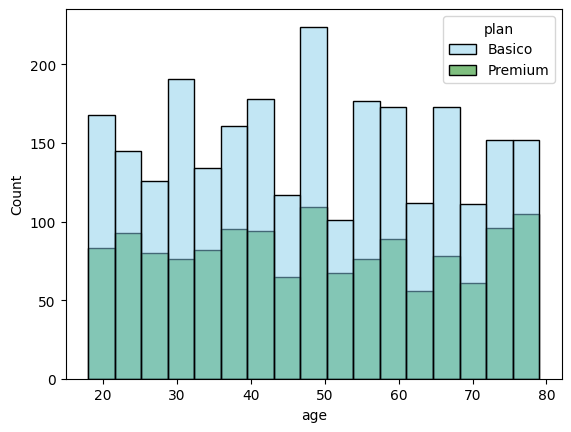

In [ ]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x="age",hue='plan', palette=['skyblue','green'])

plt.show()


💡Insights:
- Distribución: En prácticamente todos los rangos de edad, los usuarios del plan Básico superan en cantidad a los del plan Premium, lo que indica que la elección del plan no está condicionada por la edad del cliente.

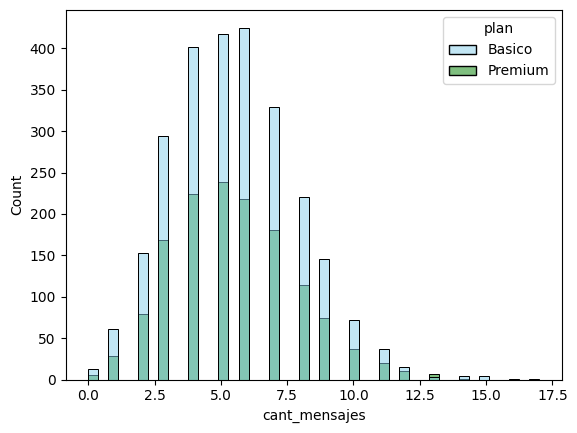

In [ ]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile, x="cant_mensajes",hue='plan', palette=['skyblue','green'])

plt.show()


💡Insights:
Distribución con ligero sesgo a la derecha: La cantidad de mensajes enviados por usuario se concentra principalmente entre 4 y 6 mensajes, con una cola ligera hacia la derecha que alcanza un máximo cercano a los 17 mensajes.
Consumo equivalente entre planes: Aunque el plan Básico registra barras más altas debido a que cuenta con una mayor base total de clientes, la forma y el centro de ambas distribuciones coinciden; esto indica que el tipo de plan no influye en la cantidad de mensajes que envía un usuario.

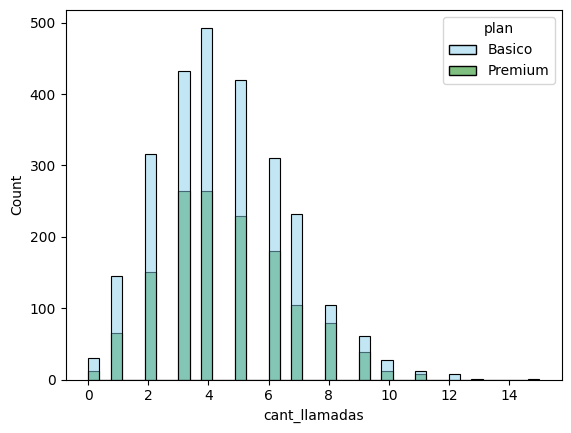

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas",hue='plan', palette=['skyblue','green'])

plt.show()

💡Insights:
Distribución concentrada y ligeramente sesgada a la derecha: La mayoría de los usuarios realiza entre 3 y 5 llamadas (con una moda clara en 4 llamadas), y presenta una cola leve hacia la derecha que llega hasta alrededor de 14–15 llamadas.   
Independencia respecto al tipo de plan: Al igual que ocurre con los mensajes, aunque el plan Básico muestra barras más altas por tener un mayor volumen de suscriptores, la forma, dispersión y tendencia central de ambos grupos son prácticamente idénticas. Esto confirma que tener un plan Premium no se traduce en realizar un mayor número de llamadas.

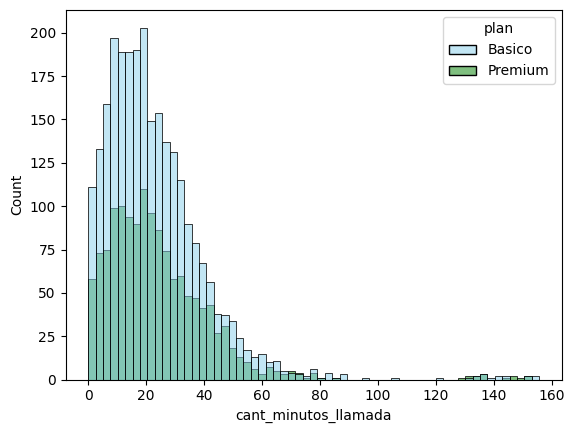

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada",hue='plan', palette=['skyblue','green'])

plt.show()

💡Insights:
La gran mayoría de los usuarios acumula entre 5 y 30 minutos de llamada (con el pico principal alrededor de los 10–20 minutos), pero existe una cola extensa hacia la derecha que llega hasta los 155–160 minutos. Este grupo reducido de usuarios con consumos extremos (entre 120 y 160 minutos) corresponde al impacto de las llamadas atípicas detectadas en el diagnóstico inicial.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

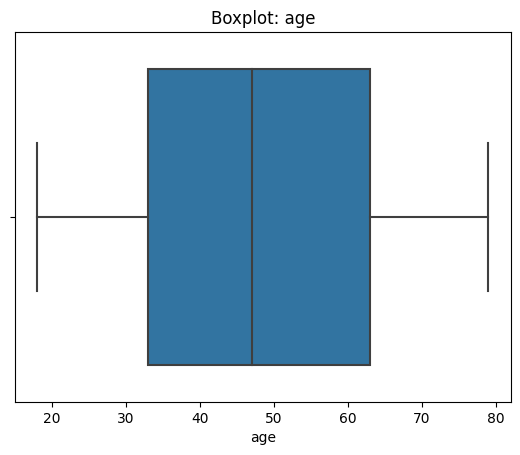

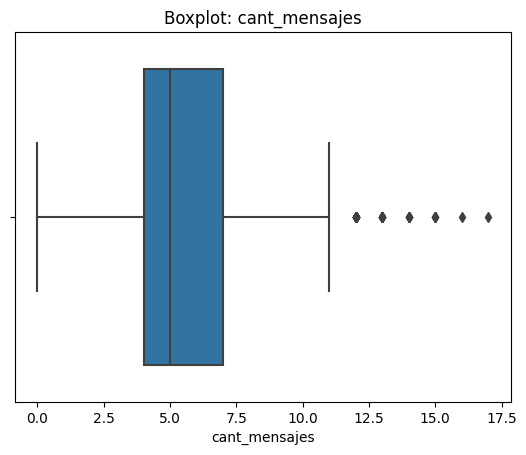

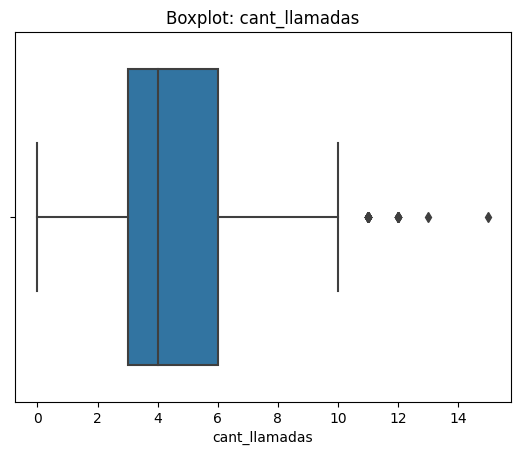

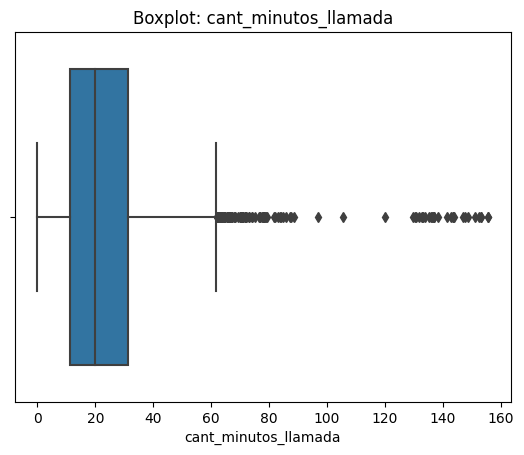

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights:
- Age: No presenta Outliners, los datos presentan uns distribucion normal.
- cant_mensajes: La mayoría de los usuarios envía entre 4 y 7 mensajes. Se identifican algunos valores atípicos que reflejan usuarios con una actividad superior al comportamiento habitual.
- cant_llamadas: La distribución se concentra entre 3 y 6 llamadas. Existen pocos usuarios con una cantidad de llamadas considerablemente superior al promedio.
- cant_minutos_llamada: La mayoría de las llamadas tiene una duración entre 11 y 31 minutos. Se observa una distribución sesgada hacia la derecha, con algunos usuarios que registran llamadas excepcionalmente largas.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f"Limite inferior de {col} es {limite_inferior}")
    print(f"Limite_superior de {col} es {limite_superior}")
    outliers = user_profile[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]
    print(f"Cantidad de outliers {col}: {len(outliers)}")


Limite inferior de cant_mensajes es -0.5
Limite_superior de cant_mensajes es 11.5
Cantidad de outliers cant_mensajes: 46
Limite inferior de cant_llamadas es -1.5
Limite_superior de cant_llamadas es 10.5
Cantidad de outliers cant_llamadas: 30
Limite inferior de cant_minutos_llamada es -19.35
Limite_superior de cant_minutos_llamada es 61.870000000000005
Cantidad de outliers cant_minutos_llamada: 109


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: Se identifican 46 valores atípicos (1,15 %). El máximo es de 17 mensajes frente a una mediana de 5. Debido a que representan una proporción pequeña de los registros y podrían reflejar usuarios con mayor interacción, se decide mantenerlos.
- cant_llamadas: Se identifican 30 valores atípicos (0,75 %). Aunque el máximo alcanza 15 llamadas y supera el comportamiento habitual, su baja proporción no justifica eliminarlos sin evidencia de errores en los datos. Se conservan para representar la actividad real de los usuarios.
- cant_minutos_llamada: Se identifican 109 valores atípicos (2,73 %), con una duración máxima de 155,69 minutos. Aunque estos registros elevan el promedio (23,31 minutos) respecto a la mediana (19,78 minutos), podrían corresponder a interacciones prolongadas legítimas. Por tanto, se mantienen y se consideran para una validación posterior.mantener o no outliers, porqué?

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso

def clasificacion(row):
    cant_mensajes = row["cant_mensajes"]
    cant_llamadas = row["cant_llamadas"]


    if cant_llamadas < 5 and cant_mensajes < 5:
        return "Bajo uso"
    elif cant_llamadas < 10 and cant_mensajes < 10:
        return "Uso medio"
    else:
        return "Alto uso"

# Crear la nueva columna
user_profile["grupo_uso"] = user_profile.apply(clasificacion, axis=1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7.0,3.0,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5.0,10.0,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso
2,10002,5.0,2.0,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11.0,3.0,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso
4,10004,4.0,3.0,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def clasificacion_edad(row):
    edad = row["age"]

    if edad <= 30:
        return "Joven"
    elif edad <= 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

# Crear la nueva columna
user_profile["grupo_edad"] = user_profile.apply(clasificacion_edad, axis=1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7.0,3.0,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5.0,10.0,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso,Adulto
2,10002,5.0,2.0,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11.0,3.0,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso,Adulto Mayor
4,10004,4.0,3.0,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

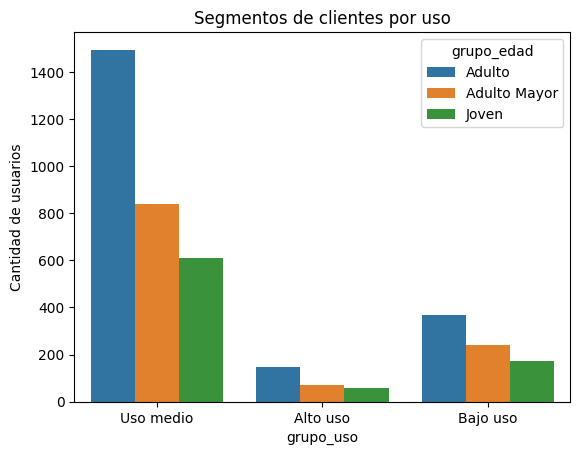

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso", hue="grupo_edad")
plt.ylabel("Cantidad de usuarios")
plt.title("Segmentos de clientes por uso")
plt.show()


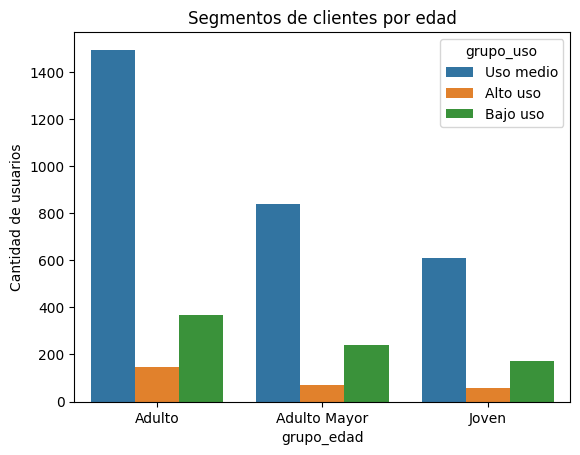

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad", hue="grupo_uso")
plt.ylabel("Cantidad de usuarios")
plt.title("Segmentos de clientes por edad")
plt.show()


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

Valores faltantes: En la columna city se encontraron 469 valores nulos (11,73%) y 96 registros con el carácter ? (2,40%), para un total de 565 usuarios sin información de ciudad (14,13%). En usage, la columna date presentó 50 registros nulos (0,13%), mientras que duration tuvo 22.076 nulos (55,19%) y length 17.896 (44,74%). Estos últimos son nulos estructurales, ya que las llamadas tienen duración y los mensajes tienen longitud de texto.

Valores inválidos: En age se identificó el valor centinela -999, que distorsionaba las estadísticas, especialmente el promedio y la desviación estándar. También se encontraron 40 fechas futuras (1%) en reg_date, correspondientes al año 2026, y 50 fechas nulas en usage.

Acciones de limpieza: Se reemplazó el valor -999 por la mediana de edad, se identificaron los valores desconocidos de ciudad y se corrigieron las fechas fuera de rango. Los nulos estructurales de duración y longitud se conservaron para evitar alterar la información.


🔍 **Segmentos por Edad**

Jóvenes (menores de 30 años): Representan el grupo con menor cantidad de usuarios. Su comportamiento se concentra principalmente en el uso medio, aunque también existe un grupo de bajo consumo. Esto representa una oportunidad para atraer nuevos clientes mediante planes económicos y paquetes flexibles.

Adultos (30 a 60 años): Constituyen el segmento más numeroso de la base de clientes. Predomina el uso medio, seguido del bajo uso. Son un grupo importante para ConnectaTel por su volumen y potencial de conversión hacia planes de mayor valor.

Adultos mayores (más de 60 años): También presentan una concentración importante de usuarios con consumo medio. Su comportamiento es relativamente similar al de los adultos, por lo que no se evidencia que la edad, por sí sola, determine un mayor o menor consumo.


📊 **Segmentos por Nivel de Uso**

Bajo uso: Son clientes que realizan menos de 5 llamadas y envían menos de 5 mensajes. Representan una oportunidad para implementar estrategias de fidelización, identificar necesidades y evitar que abandonen el servicio.

Uso medio: Es el segmento predominante en la empresa. Sus clientes realizan entre 5 y 9 llamadas o mensajes, sin superar los límites establecidos para el nivel alto. Constituyen el principal mercado potencial para ofrecer mejoras de plan y servicios adicionales.

Alto uso: Es el segmento más pequeño. Incluye usuarios que realizan 10 o más llamadas o envían 10 o más mensajes. Aunque son menos numerosos, pueden representar oportunidades comerciales por su mayor actividad y posible necesidad de servicios adicionales.


➡️ Esto sugiere que ConnectaTel tiene una base de clientes concentrada principalmente en el uso medio, independientemente del grupo de edad. Por lo tanto, las estrategias comerciales deberían priorizar el comportamiento de consumo y las necesidades de cada usuario, en lugar de segmentar únicamente por edad.

📈 Patrones de uso extremo (Outliers)

Se identificaron valores atípicos en las tres variables principales de consumo:

Mensajes: 46 usuarios (1,15%) superan el límite superior de 11,5 mensajes, alcanzando un máximo de 17 mensajes.

Llamadas: 30 usuarios (0,75%) superan el límite de 10,5 llamadas, con un máximo de 15 llamadas.

Minutos de llamadas: 109 usuarios (2,73%) superan los 61,87 minutos, llegando hasta un máximo de 155,69 minutos.

Estos valores no necesariamente representan errores, sino que pueden corresponder a clientes con necesidades de comunicación superiores al promedio. Por esta razón, se decidió conservarlos.

Para el negocio, estos usuarios representan una oportunidad para ofrecer paquetes adicionales, beneficios por fidelidad o planes con mayores capacidades. También es importante monitorear estos consumos para identificar posibles necesidades de actualización de plan.


💡 **Recomendaciones**

Crear un plan intermedio: Diseñar una alternativa entre Básico y Premium, dirigida al segmento de uso medio, que permita aumentar gradualmente los beneficios sin generar un incremento demasiado elevado en el precio mensual.

Optimizar el plan Básico: Orientarlo a clientes de bajo consumo, especialmente jóvenes y usuarios que utilizan poco el servicio, manteniendo un precio competitivo.

Fortalecer el plan Premium: Dirigirlo a clientes de alto consumo, ofreciendo mayores beneficios en llamadas y mensajes, así como ventajas para usuarios frecuentes.

Implementar estrategias de fidelización: Identificar a los clientes de bajo uso y desarrollar promociones personalizadas para incentivar su actividad y reducir el riesgo de abandono.

Ofrecer paquetes adicionales: Crear complementos de minutos y mensajes para los usuarios que superan los niveles habituales de consumo, evitando que tengan que cambiar inmediatamente de plan.

Personalizar las ofertas: Utilizar los patrones de consumo para recomendar planes según las necesidades reales de cada cliente, sin asumir que la edad determina su comportamiento.